# M1-B1 — Exploration de l'historique des réservations

Ce notebook sert aux tâches 1 à 3 : connexion à la base, exploration en SQL, chargement des données.
Crée d'autres notebooks pour la suite (par exemple `02_modelisation.ipynb`).

In [5]:
from sqlalchemy import create_engine, text
from dotenv import load_dotenv
import os

load_dotenv(override=True)

engine = create_engine(os.environ["DATABASE_URL"])

('escale', 'escale')


## Tâche 1 — La base répond-elle ?

In [6]:
pd.read_sql(text("SELECT COUNT(*) AS nb_reservations FROM reservations"), engine)

,nb_reservations
0,78703


## Tâche 2 — Explorer en SQL

Les calculs se font **dans la requête SQL** ; pandas sert seulement à afficher le résultat.

Pour commencer : les tables disponibles et leurs colonnes.

In [7]:
pd.read_sql(text("SELECT * FROM hotels"), engine)

,hotel_id,code,nom,type,ville
0,1,City Hotel,Escale Atlantique Centre,urbain,Lisbonne
1,2,Resort Hotel,Escale Atlantique Océan,resort,Algarve


In [8]:
pd.read_sql(text("SELECT * FROM reservations LIMIT 5"), engine)

,reservation_id,hotel_id,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date
0,1,1,0,6,2015,July,27,1,0,2,...,6,None,0,Transient,0.0,0,0,Check-Out,2015-07-03,2015-07-01
1,2,1,1,88,2015,July,27,1,0,4,...,9,None,0,Transient,76.5,0,1,Canceled,2015-07-01,2015-07-01
2,3,1,1,65,2015,July,27,1,0,4,...,9,None,0,Transient,68.0,0,1,Canceled,2015-04-30,2015-07-01
3,4,1,1,92,2015,July,27,1,2,4,...,9,None,0,Transient,76.5,0,2,Canceled,2015-06-23,2015-07-01
4,5,1,1,257,2015,July,27,1,0,2,...,6,None,0,Transient,101.5,0,0,Canceled,2015-06-16,2015-07-01


### Réservations et taux d'annulation par hôtel

In [16]:
query = text("""
    SELECT
        h.hotel_id,
        h.code,
        h.nom AS nom_hotel,
        h.type,
        h.ville,
        COUNT(r.reservation_id) AS nombre_reservations,
        SUM(r.is_canceled) AS nombre_annulations,
        ROUND(
            SUM(r.is_canceled) * 100.0 / COUNT(r.reservation_id),
            2
        ) AS taux_annulation
    FROM reservations r
    INNER JOIN hotels h
        ON r.hotel_id = h.hotel_id
    GROUP BY
        h.hotel_id,
        h.code,
        h.nom,
        h.type,
        h.ville
    ORDER BY taux_annulation DESC
""")
# Exécuter la requête et afficher les résultats
df_hotel = pd.read_sql(query, engine)

df_hotel

,hotel_id,code,nom_hotel,type,ville,nombre_reservations,nombre_annulations,taux_annulation
0,1,City Hotel,Escale Atlantique Centre,urbain,Lisbonne,51822,21411,41.32
1,2,Resort Hotel,Escale Atlantique Océan,resort,Algarve,26881,7068,26.29


### Taux d'annulation selon le mois d'arrivée

In [18]:
# Calculer le nombre de réservations et le taux d'annulation par mois
query = text("""
    SELECT
        arrival_date_month AS mois_arrivee,
        COUNT(reservation_id) AS nombre_reservations,
        SUM(is_canceled) AS nombre_annulations,
        ROUND(
            SUM(is_canceled) * 100.0 / COUNT(reservation_id),
            2
        ) AS taux_annulation
    FROM reservations
    GROUP BY arrival_date_month
    ORDER BY
        CASE arrival_date_month
            WHEN 'January' THEN 1
            WHEN 'February' THEN 2
            WHEN 'March' THEN 3
            WHEN 'April' THEN 4
            WHEN 'May' THEN 5
            WHEN 'June' THEN 6
            WHEN 'July' THEN 7
            WHEN 'August' THEN 8
            WHEN 'September' THEN 9
            WHEN 'October' THEN 10
            WHEN 'November' THEN 11
            WHEN 'December' THEN 12
        END
""")

# Exécuter la requête et afficher les résultats
df_mois = pd.read_sql(query, engine)

df_mois

,mois_arrivee,nombre_reservations,nombre_annulations,taux_annulation
0,January,2248,557,24.78
1,February,3891,1337,34.36
2,March,4824,1477,30.62
3,April,5428,2061,37.97
4,May,5478,1915,34.96
5,June,5292,2096,39.61
6,July,7348,2758,37.53
7,August,8952,3423,38.24
8,September,10508,4116,39.17
9,October,11160,4246,38.05


### Taux d'annulation selon le délai entre réservation et arrivée

In [20]:
# # Taux d'annulation selon le délai entre réservation et arrivée
query = text("""
    SELECT
        CASE
            WHEN lead_time BETWEEN 0 AND 7 THEN '0-7 jours'
            WHEN lead_time BETWEEN 8 AND 30 THEN '8-30 jours'
            WHEN lead_time BETWEEN 31 AND 90 THEN '31-90 jours'
            WHEN lead_time BETWEEN 91 AND 180 THEN '91-180 jours'
            WHEN lead_time BETWEEN 181 AND 365 THEN '181-365 jours'
            ELSE 'Plus de 365 jours'
        END AS tranche_delai,

        COUNT(*) AS nombre_reservations,
        SUM(is_canceled) AS nombre_annulations,

        ROUND(
            SUM(is_canceled) * 100.0 / COUNT(*),
            2
        ) AS taux_annulation

    FROM reservations
    GROUP BY tranche_delai
    ORDER BY MIN(lead_time)
""")

# Exécuter la requête et afficher les résultats
df_delai = pd.read_sql(query, engine)

df_delai


,tranche_delai,nombre_reservations,nombre_annulations,taux_annulation
0,0-7 jours,13925,1391,9.99
1,8-30 jours,12602,3342,26.52
2,31-90 jours,20140,7159,35.55
3,91-180 jours,15748,6837,43.42
4,181-365 jours,14504,8365,57.67
5,Plus de 365 jours,1784,1385,77.63


### Taux d'annulation par segment de clientèle et par type d'acompte

In [21]:
# # Taux d'annulation par segment de clientèle et type d'acompte
query = text("""
    SELECT
        customer_type AS segment_clientele,
        deposit_type AS type_acompte,

        COUNT(reservation_id) AS nombre_reservations,
        SUM(is_canceled) AS nombre_annulations,

        ROUND(
            SUM(is_canceled) * 100.0 / COUNT(reservation_id),
            2
        ) AS taux_annulation

    FROM reservations

    GROUP BY customer_type, deposit_type

    ORDER BY taux_annulation DESC
""")

# Exécuter la requête et afficher les résultats
df_segment = pd.read_sql(query, engine)

df_segment

,segment_clientele,type_acompte,nombre_reservations,nombre_annulations,taux_annulation
0,Contract,Non Refund,544,544,100.00
1,Transient,Non Refund,8796,8796,100.00
2,Transient-Party,Non Refund,1121,1036,92.42
3,Transient,No Deposit,47026,13096,27.85
4,Transient-Party,No Deposit,17860,4311,24.14
5,Contract,No Deposit,2870,641,22.33
6,Group,No Deposit,351,45,12.82
7,Transient-Party,Refundable,127,10,7.87
8,Group,Refundable,8,0,0.00


### Rapport d'étonnement

#### 1.Taux d'annulations

Le premier constat est que l'hôtel Escale Atlantique Centre possède presque deux fois plus de réservations que l'hôtel Escale Atlantique Océan. Cependant, son taux d'annulation est également supérieur de 15,03 points.

Ce résultat est particulièrement intéressant : le nombre élevé d'annulations ne s'explique pas uniquement par le volume de réservations.

#### 2. Variations des réservations et des annulations selon le mois d'arrivée 

Premier étonnement : une forte augmentation des réservations à partir de juillet.

Le nombre de réservations augmente progressivement jusqu'en octobre, qui représente le mois avec le plus grand volume de réservations. Cette évolution peut être liée à la saisonnalité touristique et aux périodes de déplacement.

Deuxième étonnement : un taux d'annulation relativement élevé pendant les mois de forte activité.

Les mois de juin, septembre et août présentent des taux d'annulation proches de 39 %. Cela montre que l'augmentation du nombre de réservations s'accompagne également d'un nombre important d'annulations.

Troisième étonnement : janvier présente le taux d'annulation le plus faible.

Avec seulement 24,78 % d'annulations, janvier se distingue nettement des autres mois. Il serait intéressant de comprendre pourquoi les réservations de cette période sont moins souvent annulées.

Quatrième étonnement : octobre possède le plus grand nombre d'annulations.

Avec 4 246 annulations, octobre arrive en tête en volume. Cependant, son taux d'annulation (38,05 %) reste inférieur à celui de juin (39,61 %) et de septembre (39,17 %).

#### 3. Taux d'annulation selon le délai entre réservation et arrivée

##### Les réservations de dernière minute sont beaucoup moins annulées.

Les réservations effectuées entre 0 et 7 jours avant l'arrivée présentent un taux d'annulation de seulement 9,99 %. Cela peut s'expliquer par le fait que les clients qui réservent au dernier moment ont souvent un projet de séjour plus immédiat.

##### Le taux d'annulation augmente avec le délai de réservation.

On constate une progression régulière du taux d'annulation lorsque le délai entre la réservation et l'arrivée augmente.

##### Les réservations très anticipées sont particulièrement exposées.

Les réservations effectuées plus de 365 jours à l'avance affichent un taux d'annulation de 77,63 %. Cela signifie que plus de trois réservations sur quatre dans cette catégorie sont annulées.

##### Un constat particulièrement étonnant :

Les réservations effectuées plus de 181 jours à l'avance présentent un taux d'annulation supérieur à 57 %. À l'inverse, les réservations de dernière minute sont nettement plus fiables.

#### 4. Taux d'annulation par segment de clientèle et par type d'acompte
L’analyse des réservations met en évidence des différences importantes de taux d’annulation selon le segment de clientèle et le type d’acompte choisi.

Le résultat le plus surprenant concerne les réservations avec un acompte non remboursable (Non Refund). Les segments Contract et Transient affichent un taux d’annulation de 100 %. Le segment Transient-Party présente également un taux très élevé de 92,42 %. Ces résultats sont particulièrement inattendus et nécessitent une vérification de la qualité des données ainsi que des règles d’enregistrement des annulations.

À l’inverse, les réservations sans acompte (No Deposit) présentent des taux d’annulation compris entre 12,82 % et 27,85 %. Le segment Transient représente le volume le plus important, avec 47 026 réservations et 13 096 annulations.

Enfin, les réservations remboursables (Refundable) semblent présenter des taux d’annulation plus faibles. Toutefois, les volumes observés sont très limités, ce qui invite à interpréter ces résultats avec prudence.

Recommandations

## Tâche 3 — Charger les données et préparer le découpage

Une seule requête SQL, avec la jointure sur `hotels` pour récupérer la colonne `hotel`
(`'City Hotel'` / `'Resort Hotel'`) attendue par la recette de la v1.

In [22]:
# Chargement des données
import pandas as pd
from sqlalchemy import text

query = text("""
    SELECT
        r.*,
        h.code AS hotel
    FROM reservations AS r
    INNER JOIN hotels AS h
        ON r.hotel_id = h.hotel_id
""")

df = pd.read_sql(query, engine)

# Convertir la date d'arrivée
df["arrival_date"] = pd.to_datetime(df["arrival_date"])

df.head()

,reservation_id,hotel_id,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,...,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date,hotel
0,1,1,0,6,2015,July,27,1,0,2,...,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-03,2015-07-01,City Hotel
1,2,1,1,88,2015,July,27,1,0,4,...,NaN,0,Transient,76.5,0,1,Canceled,2015-07-01,2015-07-01,City Hotel
2,3,1,1,65,2015,July,27,1,0,4,...,NaN,0,Transient,68.0,0,1,Canceled,2015-04-30,2015-07-01,City Hotel
3,4,1,1,92,2015,July,27,1,2,4,...,NaN,0,Transient,76.5,0,2,Canceled,2015-06-23,2015-07-01,City Hotel
4,5,1,1,257,2015,July,27,1,0,2,...,NaN,0,Transient,101.5,0,0,Canceled,2015-06-16,2015-07-01,City Hotel


In [25]:
# 2. Découpage temporel
# Date limite : 4 mois avant la dernière date d'arrivée
date_limite = df["arrival_date"].max() - pd.DateOffset(months=4)

# Entraînement sur les données passées
df_train = df[df["arrival_date"] <= date_limite].copy()

# Test sur les données les plus récentes
df_test = df[df["arrival_date"] > date_limite].copy()

print("Date limite :", date_limite)
print("Train :", df_train.shape)
print("Test :", df_test.shape)

Date limite : 2016-08-31 00:00:00
Train : (58792, 35)
Test : (19911, 35)


## Tâche 4 — Charger les données et préparer le découpage

In [26]:
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Variable cible
y_train = df_train["is_canceled"]
y_test = df_test["is_canceled"]

# Exclure la cible et les colonnes de dates
colonnes_a_exclure = [
    "is_canceled",
    "arrival_date",
    "reservation_status_date"
]

X_train = df_train.drop(
    columns=colonnes_a_exclure,
    errors="ignore"
)

X_test = df_test.drop(
    columns=colonnes_a_exclure,
    errors="ignore"
)

# Encodage des variables catégorielles
X_train = pd.get_dummies(X_train, dummy_na=True)
X_test = pd.get_dummies(X_test, dummy_na=True)

# Aligner les colonnes du test sur celles de l'entraînement
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# Remplacer les valeurs manquantes restantes
X_train = X_train.fillna(-1)
X_test = X_test.fillna(-1)

# Entraîner la forêt aléatoire
modele = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

modele.fit(X_train, y_train)

# Prédictions sur le jeu de test
y_pred = modele.predict(X_test)
y_proba = modele.predict_proba(X_test)[:, 1]

### Le score

In [27]:
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))

print("\nRapport de classification :")
print(classification_report(y_test, y_pred))

print("Matrice de confusion :")
print(confusion_matrix(y_test, y_pred))

print("ROC-AUC :", round(roc_auc_score(y_test, y_proba), 4))

Accuracy : 1.0

Rapport de classification :
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     12341
           1       1.00      1.00      1.00      7570

    accuracy                           1.00     19911
   macro avg       1.00      1.00      1.00     19911
weighted avg       1.00      1.00      1.00     19911

Matrice de confusion :
[[12341     0]
 [    0  7570]]
ROC-AUC : 1.0


### Les variables les plus importantes

In [28]:
importances = pd.DataFrame({
    "variable": X_train.columns,
    "importance": modele.feature_importances_
})

importances = importances.sort_values(
    by="importance",
    ascending=False
)

print(importances.head(20))

                          variable  importance
238   reservation_status_Check-Out    0.423822
237    reservation_status_Canceled    0.255226
229        deposit_type_Non Refund    0.053115
228        deposit_type_No Deposit    0.037643
12          previous_cancellations    0.030816
151                    country_PRT    0.025875
20       total_of_special_requests    0.020921
2                        lead_time    0.020763
239     reservation_status_No-Show    0.012941
215           assigned_room_type_A    0.010905
193          market_segment_Groups    0.007540
0                   reservation_id    0.006361
18                             adr    0.005950
15                           agent    0.005875
19     required_car_parking_spaces    0.005417
14                 booking_changes    0.005367
234        customer_type_Transient    0.004411
195       market_segment_Online TA    0.003936
4         arrival_date_week_number    0.003608
235  customer_type_Transient-Party    0.003135


### Visualisation

Matplotlib is building the font cache; this may take a moment.


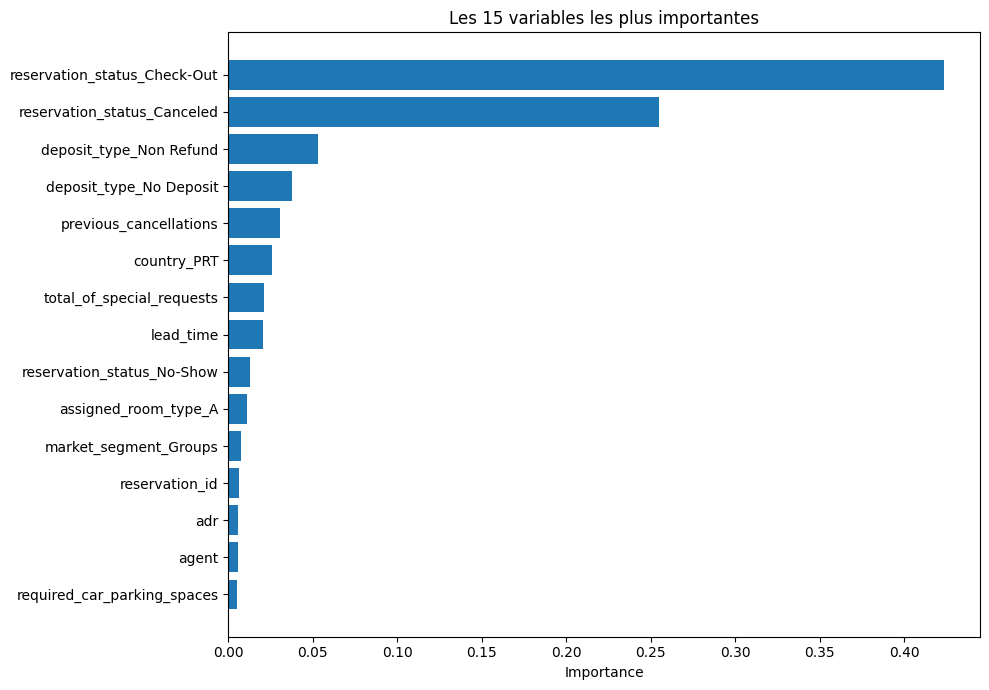

In [29]:
import matplotlib.pyplot as plt

top_variables = importances.head(15).sort_values("importance")

plt.figure(figsize=(10, 7))
plt.barh(top_variables["variable"], top_variables["importance"])
plt.xlabel("Importance")
plt.title("Les 15 variables les plus importantes")
plt.tight_layout()
plt.show()

| Variable | Moment |
|---|---|
| `reservation_id` | Création |
| `hotel_id` | Création |
| `hotel` | Création |
| `is_canceled` | Après l'évolution de la réservation |
| `lead_time` | Création |
| `arrival_date_year` | Création |
| `arrival_date_month` | Création |
| `arrival_date_week_number` | Création |
| `arrival_date_day_of_month` | Création |
| `stays_in_weekend_nights` | Création, durée prévue |
| `stays_in_week_nights` | Création, durée prévue |
| `adults` | Création |
| `children` | Création |
| `babies` | Création |
| `meal` | Création |
| `country` | Création, si renseigné |
| `market_segment` | Création |
| `distribution_channel` | Création |
| `is_repeated_guest` | Création |
| `previous_cancellations` | Création, historique connu |
| `previous_bookings_not_canceled` | Création, historique connu |
| `reserved_room_type` | Création |
| `assigned_room_type` | Attribution de chambre |
| `booking_changes` | Après création, évolue avec les modifications |
| `deposit_type` | Création |
| `agent` | Création, si l'intermédiaire est connu |
| `company` | Création, si renseignée |
| `days_in_waiting_list` | Après traitement de la demande |
| `customer_type` | Création |
| `adr` | Tarif enregistré, potentiellement évolutif |
| `required_car_parking_spaces` | Selon la disponibilité de la demande initiale |
| `total_of_special_requests` | Peut évoluer après la réservation |
| `reservation_status` | Après annulation ou fin du séjour |
| `reservation_status_date` | Lors du changement de statut |

## Tâche 5 — Exercice guidé

#### Entraînement : 58792 réservations 
#### test : 19911 réservations

### Étape 1 — Validation croisée
### Validation croisée à 5 folds :
#### F1
  ##### Train : 0.9938
  ##### Validation : 0.8853
#### PRECISION
  ##### Train : 0.9948
  ##### Validation : 0.9289
#### RECALL
  ##### Train : 0.9928
  ##### Validation : 0.8456
### Étape 2 — Surapprentissage 
#### F1 moyen entraînement : 0.9938
#### F1 moyen validation   : 0.8846
### Écart moyen           : 0.1092
#### Conclusion : écart important, risque de surapprentissage.

### Étape 3 